# Graf Berarah dan Tidak Berarah

# Import Library

Pada tahap ini dilakukan proses import library yang diperlukan untuk membuat, memvisualisasikan, dan menganalisis graph.

- Library networkx digunakan untuk membuat graph serta menghitung berbagai metrik graph. 

- Library matplotlib.pyplot digunakan untuk menampilkan visualisasi graph dan distribusi derajat. 

- Library numpy digunakan untuk pengolahan data numerik.

- Counter digunakan untuk menghitung frekuensi kemunculan setiap nilai degree.

In [2]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

# Graph Berarah dan Tidak Berarah

Pada tahap ini dilakukan pembuatan dua jenis graph, yaitu graph tidak berarah (undirected graph) menggunakan nx.Graph() dan graph berarah (directed graph) menggunakan nx.DiGraph(). Kedua graph terdiri dari 5 vertex, yaitu A, B, C, D, dan E. Selanjutnya, ditentukan hubungan antarvertex melalui penambahan edge. Graph tidak berarah memiliki 6 edge, sedangkan graph berarah memiliki 7 edge.

Graph berhasil dibuat
Jumlah vertex G1: 5
Jumlah edge G1: 6
Jumlah vertex G2: 5
Jumlah edge G2: 7


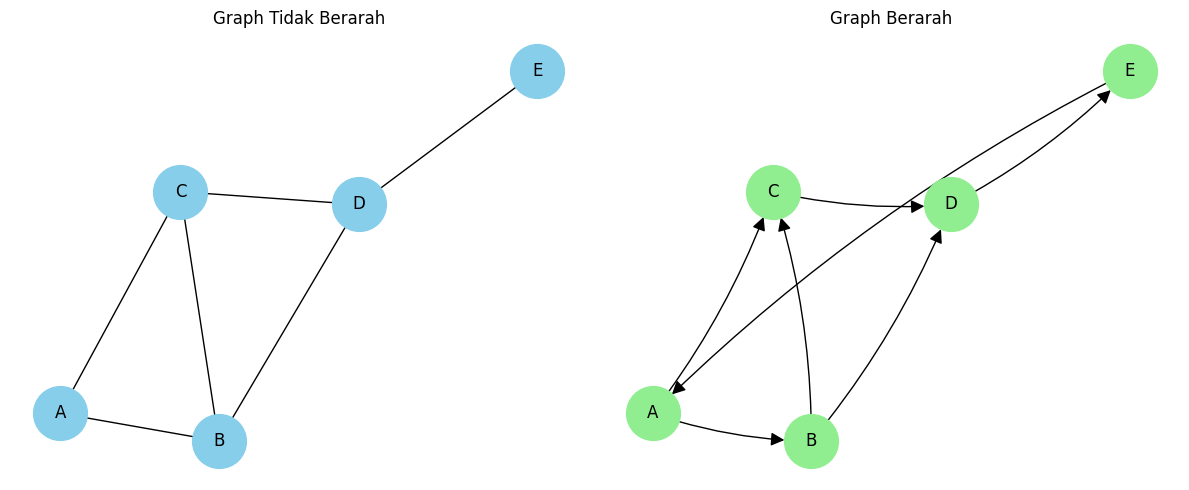

In [3]:
# Membuat graph
G1 = nx.Graph()      # Graph tidak berarah
G2 = nx.DiGraph()    # Graph berarah

# Menentukan 5 vertex
vertices = ['A', 'B', 'C', 'D', 'E']

# Menambahkan vertex
G1.add_nodes_from(vertices)
G2.add_nodes_from(vertices)

# Edge graph tidak berarah
edges_undirected = [
    ('A', 'B'),
    ('A', 'C'),
    ('B', 'C'),
    ('B', 'D'),
    ('C', 'D'),
    ('D', 'E')
]

# Edge graph berarah
edges_directed = [
    ('A', 'B'),
    ('A', 'C'),
    ('B', 'C'),
    ('B', 'D'),
    ('C', 'D'),
    ('D', 'E'),
    ('E', 'A')
]

# Menambahkan edge
G1.add_edges_from(edges_undirected)
G2.add_edges_from(edges_directed)

print("Graph berhasil dibuat")
print("Jumlah vertex G1:", G1.number_of_nodes())
print("Jumlah edge G1:", G1.number_of_edges())
print("Jumlah vertex G2:", G2.number_of_nodes())
print("Jumlah edge G2:", G2.number_of_edges())

# Menentukan posisi vertex
pos = nx.spring_layout(G1, seed=42)

plt.figure(figsize=(12, 5))

# Graph tidak berarah
plt.subplot(1, 2, 1)
nx.draw(
    G1, pos,
    with_labels=True,
    node_color="skyblue",
    node_size=1500,
    font_size=12,
    arrows=False
)
plt.title("Graph Tidak Berarah")

# Graph berarah
plt.subplot(1, 2, 2)
nx.draw(
    G2, pos,
    with_labels=True,
    node_color="lightgreen",
    node_size=1500,
    font_size=12,
    arrows=True,
    arrowsize=20,
    connectionstyle="arc3,rad=0.08"
)
plt.title("Graph Berarah")

plt.tight_layout()
plt.show()

# Menghitung Degree masing-masing Vertex

Pada tahap ini dilakukan perhitungan degree untuk mengetahui jumlah hubungan yang dimiliki setiap vertex. Pada graph tidak berarah, degree dihitung berdasarkan jumlah edge yang terhubung dengan masing-masing vertex. Sementara itu, pada graph berarah dilakukan perhitungan in-degree untuk mengetahui jumlah edge yang masuk, out-degree untuk mengetahui jumlah edge yang keluar, serta total degree yang merupakan penjumlahan in-degree dan out-degree.

In [4]:
# Degree graph tidak berarah
print("=== DEGREE GRAPH TIDAK BERARAH ===")

for node in G1.nodes():
    print(f"Vertex {node}: Degree = {G1.degree(node)}")

# Degree graph berarah
print("\n=== DEGREE GRAPH BERARAH ===")

for node in G2.nodes():
    in_degree = G2.in_degree(node)
    out_degree = G2.out_degree(node)
    total_degree = G2.degree(node)

    print(
        f"Vertex {node}: "
        f"In-Degree = {in_degree}, "
        f"Out-Degree = {out_degree}, "
        f"Total Degree = {total_degree}"
    )

=== DEGREE GRAPH TIDAK BERARAH ===
Vertex A: Degree = 2
Vertex B: Degree = 3
Vertex C: Degree = 3
Vertex D: Degree = 3
Vertex E: Degree = 1

=== DEGREE GRAPH BERARAH ===
Vertex A: In-Degree = 1, Out-Degree = 2, Total Degree = 3
Vertex B: In-Degree = 1, Out-Degree = 2, Total Degree = 3
Vertex C: In-Degree = 2, Out-Degree = 1, Total Degree = 3
Vertex D: In-Degree = 2, Out-Degree = 1, Total Degree = 3
Vertex E: In-Degree = 1, Out-Degree = 1, Total Degree = 2


# Menghitung Rata-Rata degree

Pada tahap ini dilakukan perhitungan rata-rata degree untuk mengetahui rata-rata jumlah hubungan yang dimiliki vertex dalam graph. Perhitungan dilakukan dengan menjumlahkan seluruh degree vertex, kemudian membaginya dengan jumlah vertex. Pada graph berarah, rata-rata degree dihitung menggunakan total degree, yaitu jumlah in-degree dan out-degree. Hasil perhitungan digunakan untuk membandingkan tingkat keterhubungan kedua graph.

In [5]:
# Rata-rata degree graph tidak berarah
avg_degree_G1 = sum(dict(G1.degree()).values()) / G1.number_of_nodes()

# Rata-rata total degree graph berarah
avg_degree_G2 = sum(dict(G2.degree()).values()) / G2.number_of_nodes()

print("=== RATA-RATA DEGREE ===")
print(f"Graph Tidak Berarah: {avg_degree_G1:.4f}")
print(f"Graph Berarah: {avg_degree_G2:.4f}")

=== RATA-RATA DEGREE ===
Graph Tidak Berarah: 2.4000
Graph Berarah: 2.8000


# Menghitung Koefisien Klasterisasi Setiap Vertex

Pada tahap ini dilakukan perhitungan koefisien klasterisasi (clustering coefficient) untuk mengetahui tingkat keterhubungan antarvertex yang menjadi tetangga dari suatu vertex. Perhitungan dilakukan menggunakan fungsi nx.clustering() untuk memperoleh nilai koefisien klasterisasi masing-masing vertex pada graph berarah dan tidak berarah. Selanjutnya, fungsi nx.average_clustering() digunakan untuk menghitung rata-rata koefisien klasterisasi seluruh vertex pada masing-masing graph.

In [6]:
# Koefisien klasterisasi
clustering_G1 = nx.clustering(G1)
clustering_G2 = nx.clustering(G2)

print("=== CLUSTERING GRAPH TIDAK BERARAH ===")

for node, nilai in clustering_G1.items():
    print(f"Vertex {node}: {nilai:.4f}")

print("\n=== CLUSTERING GRAPH BERARAH ===")

for node, nilai in clustering_G2.items():
    print(f"Vertex {node}: {nilai:.4f}")

# Rata-rata koefisien klasterisasi
print("\n=== RATA-RATA CLUSTERING ===")
print(f"Graph Tidak Berarah: {nx.average_clustering(G1):.4f}")
print(f"Graph Berarah: {nx.average_clustering(G2):.4f}")

=== CLUSTERING GRAPH TIDAK BERARAH ===
Vertex A: 1.0000
Vertex B: 0.6667
Vertex C: 0.6667
Vertex D: 0.3333
Vertex E: 0.0000

=== CLUSTERING GRAPH BERARAH ===
Vertex A: 0.1667
Vertex B: 0.3333
Vertex C: 0.3333
Vertex D: 0.1667
Vertex E: 0.0000

=== RATA-RATA CLUSTERING ===
Graph Tidak Berarah: 0.5333
Graph Berarah: 0.2000


# Menghitung Rata-Rata Panjang Lintasan Terpendek

Pada tahap ini dilakukan perhitungan rata-rata panjang lintasan terpendek (average shortest path length) untuk mengetahui rata-rata jumlah edge minimum yang harus dilalui dari satu vertex menuju vertex lainnya. Perhitungan menggunakan fungsi nx.average_shortest_path_length().

In [7]:
print("=== RATA-RATA LINTASAN TERPENDEK ===")

# Graph tidak berarah
if nx.is_connected(G1):
    avg_path_G1 = nx.average_shortest_path_length(G1)
    print(f"Graph Tidak Berarah: {avg_path_G1:.4f}")
else:
    print("Graph Tidak Berarah: Tidak terhubung")

# Graph berarah
if nx.is_strongly_connected(G2):
    avg_path_G2 = nx.average_shortest_path_length(G2)
    print(f"Graph Berarah: {avg_path_G2:.4f}")
else:
    print("Graph Berarah: Tidak strongly connected")

=== RATA-RATA LINTASAN TERPENDEK ===
Graph Tidak Berarah: 1.5000
Graph Berarah: 2.0500


# Menghitung Distribusi Derajat

Pada tahap ini dilakukan perhitungan distribusi derajat (degree distribution) untuk mengetahui penyebaran jumlah hubungan yang dimiliki vertex dalam graph. Program menghitung frekuensi kemunculan setiap nilai degree menggunakan Counter. Selanjutnya, probabilitas distribusi derajat dihitung dengan membagi jumlah vertex yang memiliki degree tertentu dengan jumlah seluruh vertex. Pada graph berarah, distribusi dihitung berdasarkan total degree.

=== DISTRIBUSI DERAJAT GRAPH TIDAK BERARAH ===
Degree 1: 1 vertex, P(k) = 0.2000
Degree 2: 1 vertex, P(k) = 0.2000
Degree 3: 3 vertex, P(k) = 0.6000

=== DISTRIBUSI DERAJAT GRAPH BERARAH ===
Degree 2: 1 vertex, P(k) = 0.2000
Degree 3: 4 vertex, P(k) = 0.8000


<Figure size 1200x500 with 0 Axes>

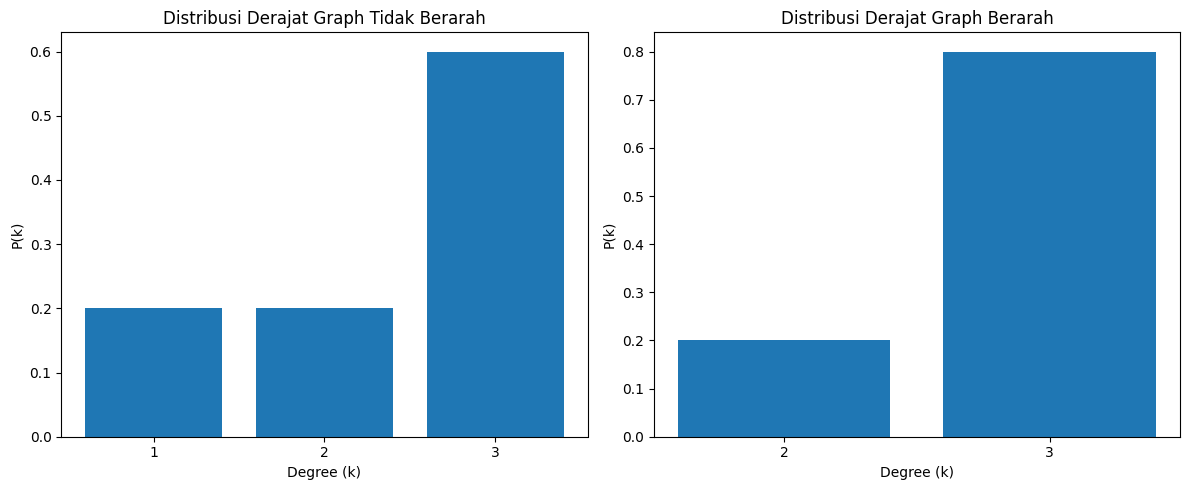

In [8]:
# Mengambil degree
degree_G1 = dict(G1.degree())
degree_G2 = dict(G2.degree())

# Menghitung distribusi
distribusi_G1 = Counter(degree_G1.values())
distribusi_G2 = Counter(degree_G2.values())

print("=== DISTRIBUSI DERAJAT GRAPH TIDAK BERARAH ===")

for k in sorted(distribusi_G1):
    jumlah = distribusi_G1[k]
    probabilitas = jumlah / G1.number_of_nodes()

    print(f"Degree {k}: {jumlah} vertex, P(k) = {probabilitas:.4f}")

print("\n=== DISTRIBUSI DERAJAT GRAPH BERARAH ===")

for k in sorted(distribusi_G2):
    jumlah = distribusi_G2[k]
    probabilitas = jumlah / G2.number_of_nodes()

    print(f"Degree {k}: {jumlah} vertex, P(k) = {probabilitas:.4f}")

    plt.figure(figsize=(12, 5))

# Distribusi graph tidak berarah
plt.subplot(1, 2, 1)

k1 = sorted(distribusi_G1)
p1 = [distribusi_G1[k] / G1.number_of_nodes() for k in k1]

plt.bar(k1, p1)
plt.xlabel("Degree (k)")
plt.ylabel("P(k)")
plt.title("Distribusi Derajat Graph Tidak Berarah")
plt.xticks(k1)

# Distribusi graph berarah
plt.subplot(1, 2, 2)

k2 = sorted(distribusi_G2)
p2 = [distribusi_G2[k] / G2.number_of_nodes() for k in k2]

plt.bar(k2, p2)
plt.xlabel("Degree (k)")
plt.ylabel("P(k)")
plt.title("Distribusi Derajat Graph Berarah")
plt.xticks(k2)

plt.tight_layout()
plt.show()

Hasil menunjukkan bahwa pada graph tidak berarah, sebagian besar vertex memiliki 3 hubungan. Sedangkan pada graph berarah, sebagian besar vertex juga memiliki 3 hubungan. Artinya, graph berarah memiliki jumlah hubungan antarvertex yang lebih merata dibandingkan graph tidak berarah.

# Menghitung Density Graph

Pada tahap ini dilakukan perhitungan kepadatan graph (graph density) untuk mengetahui seberapa banyak edge yang terbentuk dibandingkan dengan jumlah maksimum edge yang mungkin terbentuk. Perhitungan dilakukan menggunakan fungsi nx.density().

In [9]:
# Menghitung density
density_G1 = nx.density(G1)
density_G2 = nx.density(G2)

print("=== DENSITY GRAPH ===")
print(f"Graph Tidak Berarah: {density_G1:.4f}")
print(f"Graph Berarah: {density_G2:.4f}")

=== DENSITY GRAPH ===
Graph Tidak Berarah: 0.6000
Graph Berarah: 0.3500


# Adjacency Matrix

Pada tahap ini dilakukan pembuatan matriks ketetanggaan (adjacency matrix) untuk merepresentasikan hubungan antarvertex dalam bentuk matriks. Matriks dibuat menggunakan fungsi nx.to_numpy_array(). Nilai 1 menunjukkan adanya hubungan antara dua vertex, sedangkan nilai 0 menunjukkan tidak adanya hubungan. Pada graph tidak berarah, matriks bersifat simetris, sedangkan pada graph berarah matriks tidak harus simetris karena hubungan memiliki arah tertentu.

In [10]:
# Membuat fungsi adjacency matrix
def tampilkan_matriks(G, nama):
    nodes = sorted(G.nodes())
    matriks = nx.to_numpy_array(
        G,
        nodelist=nodes,
        dtype=int
    )

    print(f"\n=== ADJACENCY MATRIX {nama} ===")
    print("    " + "  ".join(nodes))

    for i, node in enumerate(nodes):
        nilai = "  ".join(map(str, matriks[i]))
        print(f"{node}   {nilai}")

# Menampilkan adjacency matrix
tampilkan_matriks(G1, "GRAPH TIDAK BERARAH")
tampilkan_matriks(G2, "GRAPH BERARAH")


=== ADJACENCY MATRIX GRAPH TIDAK BERARAH ===
    A  B  C  D  E
A   0  1  1  0  0
B   1  0  1  1  0
C   1  1  0  1  0
D   0  1  1  0  1
E   0  0  0  1  0

=== ADJACENCY MATRIX GRAPH BERARAH ===
    A  B  C  D  E
A   0  1  1  0  0
B   0  0  1  1  0
C   0  0  0  1  0
D   0  0  0  0  1
E   1  0  0  0  0


Hasil adjacency matrix menunjukkan hubungan antarvertex, dengan angka 1 berarti terhubung dan 0 berarti tidak terhubung. Pada graph tidak berarah, hubungan berlaku dua arah sehingga matriks simetris. Sedangkan pada graph berarah, hubungan mengikuti arah panah sehingga matriks tidak simetris.